# Лабораторная работа №1: Регрессионный анализ и исследование данных Bitcoin

## О формате сдачи

- Используется исходная структура заданий лабораторной работы.
- Для всех вычислительных выводов приведён код.
- Тестовая часть временного ряда откладывается **до EDA**, чтобы не использовать её при выборе признаков и формулировании выводов.
- Данные загружаются непосредственно с Kaggle через `kagglehub`.

## Этапы

### Задание 1 [4 балла]
Выберите датасет и задачу регрессии (Kaggle или UCI, не менее 100 объектов), выполните EDA и сформулируйте вопросы, требующие:

1. `groupby` + агрегации;
2. `resample`;
3. `merge` / `join` / `concat`;
4. статическую визуализацию `seaborn`;
5. интерактивную визуализацию `plotly`;
6. визуализацию распределений: histogram, KDE, boxplot, violinplot, scatter;
7. тесты свойств распределений;
8. One Hot Encoding категориальных признаков.

In [ ]:
%pip install -q kagglehub pandas numpy scipy scikit-learn seaborn matplotlib plotly

## 0. Загрузка и подготовка данных

Используется набор **Bitcoin Prices Dataset** с Kaggle:
`amineipad/bitcoin-prices-dataset`.

Задача моделирования ниже будет сформулирована как **прогноз цены закрытия следующего дня** по информации, уже известной к концу текущего дня. Это позволяет явно контролировать временную причинность и избегать look-ahead leakage.

In [2]:
from pathlib import Path
import re

import kagglehub
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from scipy import stats
from IPython.display import display

from sklearn.base import clone
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, TimeSeriesSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

pd.set_option('display.max_columns', 100)
pd.set_option('display.float_format', lambda x: f'{x:,.4f}')
sns.set_theme(style='whitegrid')

# Download latest version
path = kagglehub.dataset_download("amineipad/bitcoin-prices-dataset")
print("Kaggle dataset directory:", path)

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 163k/163k [00:00<00:00, 543kB/s]

Extracting files...
Kaggle dataset directory: /Users/moladoe/.cache/kagglehub/datasets/amineipad/bitcoin-prices-dataset/versions/1


In [3]:
# KaggleHub помещает файлы в версионируемую директорию.
# Ищем CSV, содержащий обязательные OHLCV-поля, а не полагаемся на имя файла.

def _norm_name(name: str) -> str:
    return re.sub(r'[^a-z0-9]+', '', str(name).strip().lower())

aliases = {
    'Date': {'date', 'datetime', 'timestamp', 'time'},
    'Open': {'open', 'openprice', '24open'},
    'High': {'high', 'highprice', '24high'},
    'Low': {'low', 'lowprice', '24low'},
    'Close': {'close', 'closeprice', 'closingprice'},
    'Volume': {'volume', 'vol', 'tradingvolume', '24hvolume'},
}

csv_files = sorted(Path(path).rglob('*.csv'))
if not csv_files:
    raise FileNotFoundError(f"В директории {path!r} не найдено CSV-файлов")

selected_file = None
rename_map = None

for file in csv_files:
    try:
        sample = pd.read_csv(file, nrows=5)
    except Exception:
        continue

    normalized = {_norm_name(c): c for c in sample.columns}
    current_map = {}
    ok = True
    for canonical, variants in aliases.items():
        match = next((normalized[v] for v in variants if v in normalized), None)
        if match is None:
            ok = False
            break
        current_map[match] = canonical

    if ok:
        selected_file = file
        rename_map = current_map
        break

if selected_file is None:
    print("Найденные CSV-файлы:")
    for f in csv_files:
        print(" -", f)
    raise ValueError("Не найден CSV с колонками Date/Timestamp, Open, High, Low, Close, Volume")

raw = pd.read_csv(selected_file).rename(columns=rename_map)
df = raw[['Date', 'Open', 'High', 'Low', 'Close', 'Volume']].copy()

# Date/Timestamp -> datetime
if pd.api.types.is_numeric_dtype(df['Date']):
    med = pd.to_numeric(df['Date'], errors='coerce').median()
    if med > 1e14:
        unit = 'ns'
    elif med > 1e11:
        unit = 'ms'
    elif med > 1e8:
        unit = 's'
    else:
        unit = None
    df['Date'] = pd.to_datetime(df['Date'], unit=unit, errors='coerce', utc=True)
else:
    df['Date'] = pd.to_datetime(df['Date'], errors='coerce', utc=True)

df['Date'] = df['Date'].dt.tz_convert(None)

# OHLCV -> numeric
for col in ['Open', 'High', 'Low', 'Close', 'Volume']:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '', regex=False).str.strip(),
        errors='coerce'
    )

before = len(df)
df = (
    df.dropna(subset=['Date', 'Open', 'High', 'Low', 'Close', 'Volume'])
      .drop_duplicates(subset='Date', keep='last')
      .sort_values('Date')
      .reset_index(drop=True)
)

# Базовые физические проверки для OHLCV
valid = (
    (df[['Open', 'High', 'Low', 'Close']] > 0).all(axis=1)
    & (df['Volume'] >= 0)
    & (df['High'] >= df[['Open', 'Close', 'Low']].max(axis=1))
    & (df['Low'] <= df[['Open', 'Close', 'High']].min(axis=1))
)
invalid_count = int((~valid).sum())
df = df.loc[valid].reset_index(drop=True)

if len(df) < 100:
    raise ValueError(f"После очистки осталось только {len(df)} строк; требуется минимум 100")

print("Используемый файл:", selected_file)
print(f"Строк до очистки: {before:,}; после очистки: {len(df):,}")
print(f"Отброшено строк, нарушающих базовые OHLCV-ограничения: {invalid_count:,}")
print("Период:", df['Date'].min().date(), "—", df['Date'].max().date())
display(df.head())
display(df.describe(include='all'))

Используемый файл: /Users/moladoe/.cache/kagglehub/datasets/amineipad/bitcoin-prices-dataset/versions/1/bitcoin.csv
Строк до очистки: 5,883; после очистки: 5,883
Отброшено строк, нарушающих базовые OHLCV-ограничения: 0
Период: 2010-01-01 — 2026-02-08


,Date,Open,High,Low,Close,Volume
0,2010-01-01,0.3000,0.3034,0.2955,0.3000,715.8000
1,2010-01-02,0.3000,0.3044,0.2995,0.3000,"2,028.3000"
2,2010-01-03,0.3000,0.3037,0.2959,0.3000,273.0000
3,2010-01-04,0.3000,0.3034,0.2985,0.3000,"1,452.0000"
4,2010-01-05,0.3000,0.3027,0.2963,0.3000,"1,002.6000"


,Date,Open,High,Low,Close,Volume
count,5883,"5,883.0000","5,883.0000","5,883.0000","5,883.0000","5,883.0000"
mean,2018-01-20 00:00:00,"21,725.0511","21,973.7162","21,487.5762","21,736.7798","108,791,503.1032"
min,2010-01-01 00:00:00,0.3000,0.3003,0.2940,0.3000,30.3000
25%,2014-01-10 12:00:00,430.5700,431.2114,422.1345,430.5700,"1,271,205.3150"
50%,2018-01-20 00:00:00,"7,193.6000","7,207.9790","7,057.9718","7,193.6000","17,568,092.4000"
75%,2022-01-29 12:00:00,"42,265.1900","42,370.1357","41,483.5788","42,265.1900","130,229,682.1050"
max,2026-02-08 00:00:00,"93,429.2000","95,281.0119","93,326.4455","93,429.2000","932,516,845.2000"
std,NaN,"30,114.9787","30,445.2565","29,793.0298","30,119.9523","185,109,840.6663"


### Защита от утечки до EDA

Для временных данных случайное перемешивание не используется. Последние 20% наблюдений резервируются как hold-out. В **Задании 1** все исследовательские графики и статистики считаются только по первым 80%, а отложенная часть не используется для выбора признаков и выводов.

In [4]:
split_idx = int(len(df) * 0.80)
eda_train = df.iloc[:split_idx].copy()
holdout_raw = df.iloc[split_idx:].copy()
split_date = eda_train['Date'].max()

# Искусственный категориальный признак только для EDA/OHE.
# rank(method='first') гарантирует 3 группы даже при совпадающих ценах.
eda_train['PriceCategory'] = pd.qcut(
    eda_train['Close'].rank(method='first'),
    q=3,
    labels=['Low', 'Medium', 'High']
)
eda_train['Intraday_Spread'] = eda_train['High'] - eda_train['Low']

print(f"EDA/train: {len(eda_train):,} строк, до {split_date.date()} включительно")
print(f"Hold-out:  {len(holdout_raw):,} строк, с {holdout_raw['Date'].min().date()}")

EDA/train: 4,706 строк, до 2022-11-19 включительно
Hold-out:  1,177 строк, с 2022-11-20


# Задание 1. EDA

## 1. Группировка с агрегацией (`groupby`)

**Вопрос:** как различаются среднее, медиана и стандартное отклонение торгового объёма и внутридневного размаха

\[
Spread = High - Low
\]

между тремя ценовыми категориями `Low`, `Medium`, `High`?

In [5]:
groupby_res = (
    eda_train.groupby('PriceCategory', observed=False)
    .agg(
        Mean_Spread=('Intraday_Spread', 'mean'),
        Median_Spread=('Intraday_Spread', 'median'),
        Std_Spread=('Intraday_Spread', 'std'),
        Mean_Volume=('Volume', 'mean'),
        Median_Volume=('Volume', 'median'),
        Std_Volume=('Volume', 'std'),
        Count=('Close', 'size'),
    )
)
display(groupby_res)

print("Интерпретация:")
for cat, row in groupby_res.iterrows():
    print(
        f"{cat}: mean spread={row['Mean_Spread']:.4f}, "
        f"median spread={row['Median_Spread']:.4f}, "
        f"mean volume={row['Mean_Volume']:.4f}, n={int(row['Count'])}"
    )

,Mean_Spread,Median_Spread,Std_Spread,Mean_Volume,Median_Volume,Std_Volume,Count
PriceCategory,,,,,,,
Low,2.6377,0.1686,12.2525,"535,762.8142","40,346.7200","945,635.5563",1569
Medium,59.0130,21.9404,290.5896,"11,726,252.5123","5,187,199.0100","15,034,470.6182",1568
High,571.3074,413.4471,"1,133.5761","125,557,680.3149","95,212,646.7600","107,690,813.2358",1569


Интерпретация:
Low: mean spread=2.6377, median spread=0.1686, mean volume=535762.8142, n=1569
Medium: mean spread=59.0130, median spread=21.9404, mean volume=11726252.5123, n=1568
High: mean spread=571.3074, median spread=413.4471, mean volume=125557680.3149, n=1569


**Вывод:** `groupby` позволяет сравнить условные распределения признаков внутри категорий. Среднее чувствительнее к редким крупным значениям, медиана устойчивее, а стандартное отклонение показывает разброс. Поскольку категории были построены из цены только для демонстрации OHE/EDA, этот признак **не используется как регрессор** при прогнозировании цены.

## 2. Изменение дискретности по времени (`resample`)

**Вопрос:** как изменяются средняя цена закрытия и суммарный объём при переходе от ежедневной к годовой дискретности?

,Mean_Close,Total_Volume,Max_High,Min_Low,Observations
Date,,,,,
2010-12-31,0.3000,"536,376.9000",0.3060,0.2940,365
2011-12-31,4.6100,"8,427,112.2700",4.7021,0.2971,365
2012-12-31,13.5300,"25,463,879.4300",13.8006,4.6049,366
2013-12-31,754.0100,"1,348,434,537.5100",769.0619,13.3772,365
2014-12-31,320.1900,"598,951,576.4700",767.6881,313.7917,365
2015-12-31,430.5700,"755,297,713.1700",439.1667,318.6571,365
2016-12-31,963.7400,"1,780,338,104.2800",982.9434,424.8827,366
2017-12-31,"14,156.4000","25,624,825,237.2000","14,439.5183",954.8034,365
2018-12-31,"3,742.7000","6,818,525,714.0000","14,418.4265","3,667.9274",365


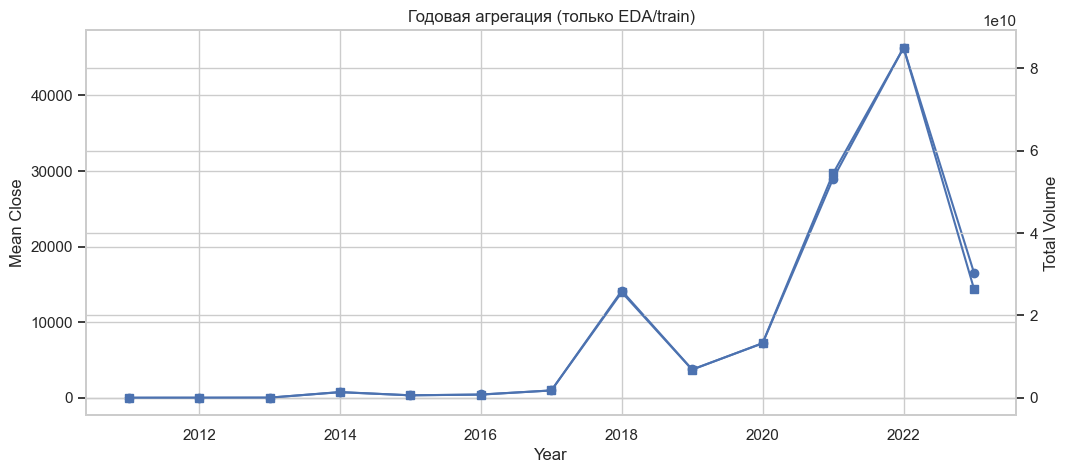

In [6]:
indexed = eda_train.set_index('Date')
try:
    yearly = indexed.resample('YE').agg(
        Mean_Close=('Close', 'mean'),
        Total_Volume=('Volume', 'sum'),
        Max_High=('High', 'max'),
        Min_Low=('Low', 'min'),
        Observations=('Close', 'size'),
    )
except ValueError:  # совместимость со старыми версиями pandas
    yearly = indexed.resample('Y').agg(
        Mean_Close=('Close', 'mean'),
        Total_Volume=('Volume', 'sum'),
        Max_High=('High', 'max'),
        Min_Low=('Low', 'min'),
        Observations=('Close', 'size'),
    )

display(yearly)

fig, ax1 = plt.subplots(figsize=(12, 5))
ax1.plot(yearly.index, yearly['Mean_Close'], marker='o', label='Mean Close')
ax1.set_ylabel('Mean Close')
ax1.set_xlabel('Year')
ax1.set_title('Годовая агрегация (только EDA/train)')
ax2 = ax1.twinx()
ax2.plot(yearly.index, yearly['Total_Volume'], marker='s', label='Total Volume')
ax2.set_ylabel('Total Volume')
plt.show()

**Вывод:** ресемплирование меняет временную гранулярность и упрощает анализ долгосрочной динамики. Для `Close` используется среднее, а для `Volume` — сумма. Если первый или последний год содержит не полный набор дат, его суммарный объём нельзя напрямую сравнивать с полными годами без учёта числа наблюдений.

## 3. Объединение датафреймов (`merge`)

**Вопрос:** как присоединить к исходным котировкам отдельно рассчитанные 7- и 30-дневные скользящие средние?

Чтобы индикаторы могли быть использованы в будущей прогнозной модели без look-ahead, здесь они рассчитываются только по **предыдущим** значениям `Close` (`shift(1)`).

In [7]:
indicators = eda_train[['Date', 'Close']].copy()
indicators['SMA_7_prev'] = indicators['Close'].shift(1).rolling(7).mean()
indicators['SMA_30_prev'] = indicators['Close'].shift(1).rolling(30).mean()
indicators = indicators[['Date', 'SMA_7_prev', 'SMA_30_prev']]

merged = eda_train.merge(indicators, on='Date', how='left', validate='one_to_one')
display(merged[['Date', 'Close', 'SMA_7_prev', 'SMA_30_prev']].head(35))

,Date,Close,SMA_7_prev,SMA_30_prev
0,2010-01-01,0.3000,NaN,NaN
1,2010-01-02,0.3000,NaN,NaN
2,2010-01-03,0.3000,NaN,NaN
3,2010-01-04,0.3000,NaN,NaN
4,2010-01-05,0.3000,NaN,NaN
5,2010-01-06,0.3000,NaN,NaN
6,2010-01-07,0.3000,NaN,NaN
7,2010-01-08,0.3000,0.3000,NaN
8,2010-01-09,0.3000,0.3000,NaN
9,2010-01-10,0.3000,0.3000,NaN


**Вывод:** `left merge` сохраняет все строки основной таблицы и добавляет совпадающие индикаторы по `Date`. Первые значения SMA равны `NaN`, потому что для них ещё нет полного окна предыдущих наблюдений.

## 4. Статическая визуализация `seaborn`

**Вопрос:** какова структура линейных связей между числовыми признаками и есть ли сильная корреляция между ценовыми регрессорами?

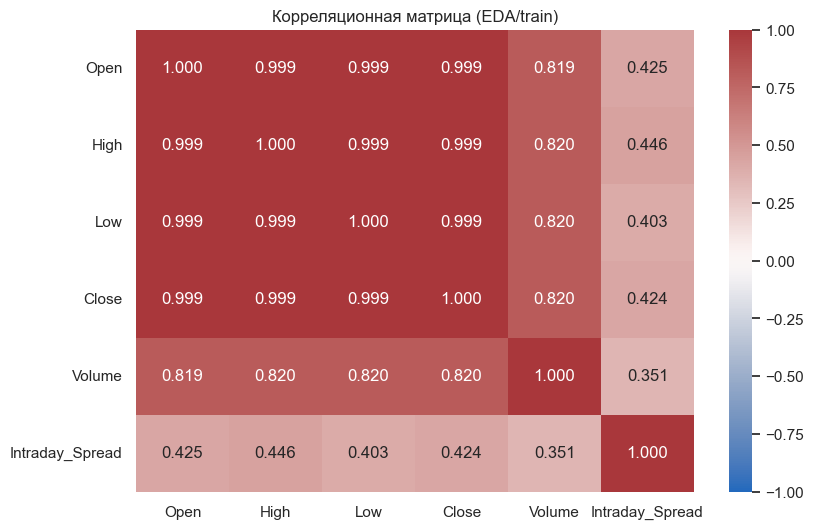

,Open,High,Low,Close,Volume,Intraday_Spread
Open,1.0000,0.9994,0.9994,0.9989,0.8188,0.4249
High,0.9994,1.0000,0.9989,0.9994,0.8197,0.4460
Low,0.9994,0.9989,1.0000,0.9994,0.8196,0.4028
Close,0.9989,0.9994,0.9994,1.0000,0.8203,0.4243
Volume,0.8188,0.8197,0.8196,0.8203,1.0000,0.3509
Intraday_Spread,0.4249,0.4460,0.4028,0.4243,0.3509,1.0000


In [8]:
num_cols = ['Open', 'High', 'Low', 'Close', 'Volume', 'Intraday_Spread']
corr = eda_train[num_cols].corr()

plt.figure(figsize=(9, 6))
sns.heatmap(corr, annot=True, fmt='.3f', vmin=-1, vmax=1, cmap='vlag')
plt.title('Корреляционная матрица (EDA/train)')
plt.show()

display(corr)

**Вывод:** корреляция измеряет линейную связь. Для OHLC-цен обычно ожидается сильная взаимная корреляция, поэтому при интерпретации отдельных коэффициентов линейной модели необходимо учитывать мультиколлинеарность. Сама по себе высокая корреляция с таргетом не является мультиколлинеарностью — она относится именно к взаимосвязям **между регрессорами**.

## 5. Интерактивный график `plotly`

**Вопрос:** как интерактивно исследовать динамику цены и объёма с общим временным масштабом и `range slider`?

In [9]:
fig = make_subplots(
    rows=2, cols=1, shared_xaxes=True,
    vertical_spacing=0.05, row_heights=[0.7, 0.3],
    subplot_titles=('Close', 'Volume')
)
fig.add_trace(
    go.Scatter(x=eda_train['Date'], y=eda_train['Close'], name='Close', mode='lines'),
    row=1, col=1
)
fig.add_trace(
    go.Bar(x=eda_train['Date'], y=eda_train['Volume'], name='Volume'),
    row=2, col=1
)
fig.update_layout(height=650, title='Bitcoin: цена и объём (EDA/train)', hovermode='x unified')
fig.update_xaxes(rangeslider_visible=True, row=2, col=1)
fig.show()

**Вывод:** интерактивный график удобен для локального анализа отдельных интервалов и совместного просмотра цены и объёма. Визуальное совпадение пиков не доказывает причинно-следственную связь.

## 6. Визуализация распределений

**Вопрос:** что показывают гистограмма относительных частот, KDE, boxplot, violinplot и scatter plot для обучающей части данных?

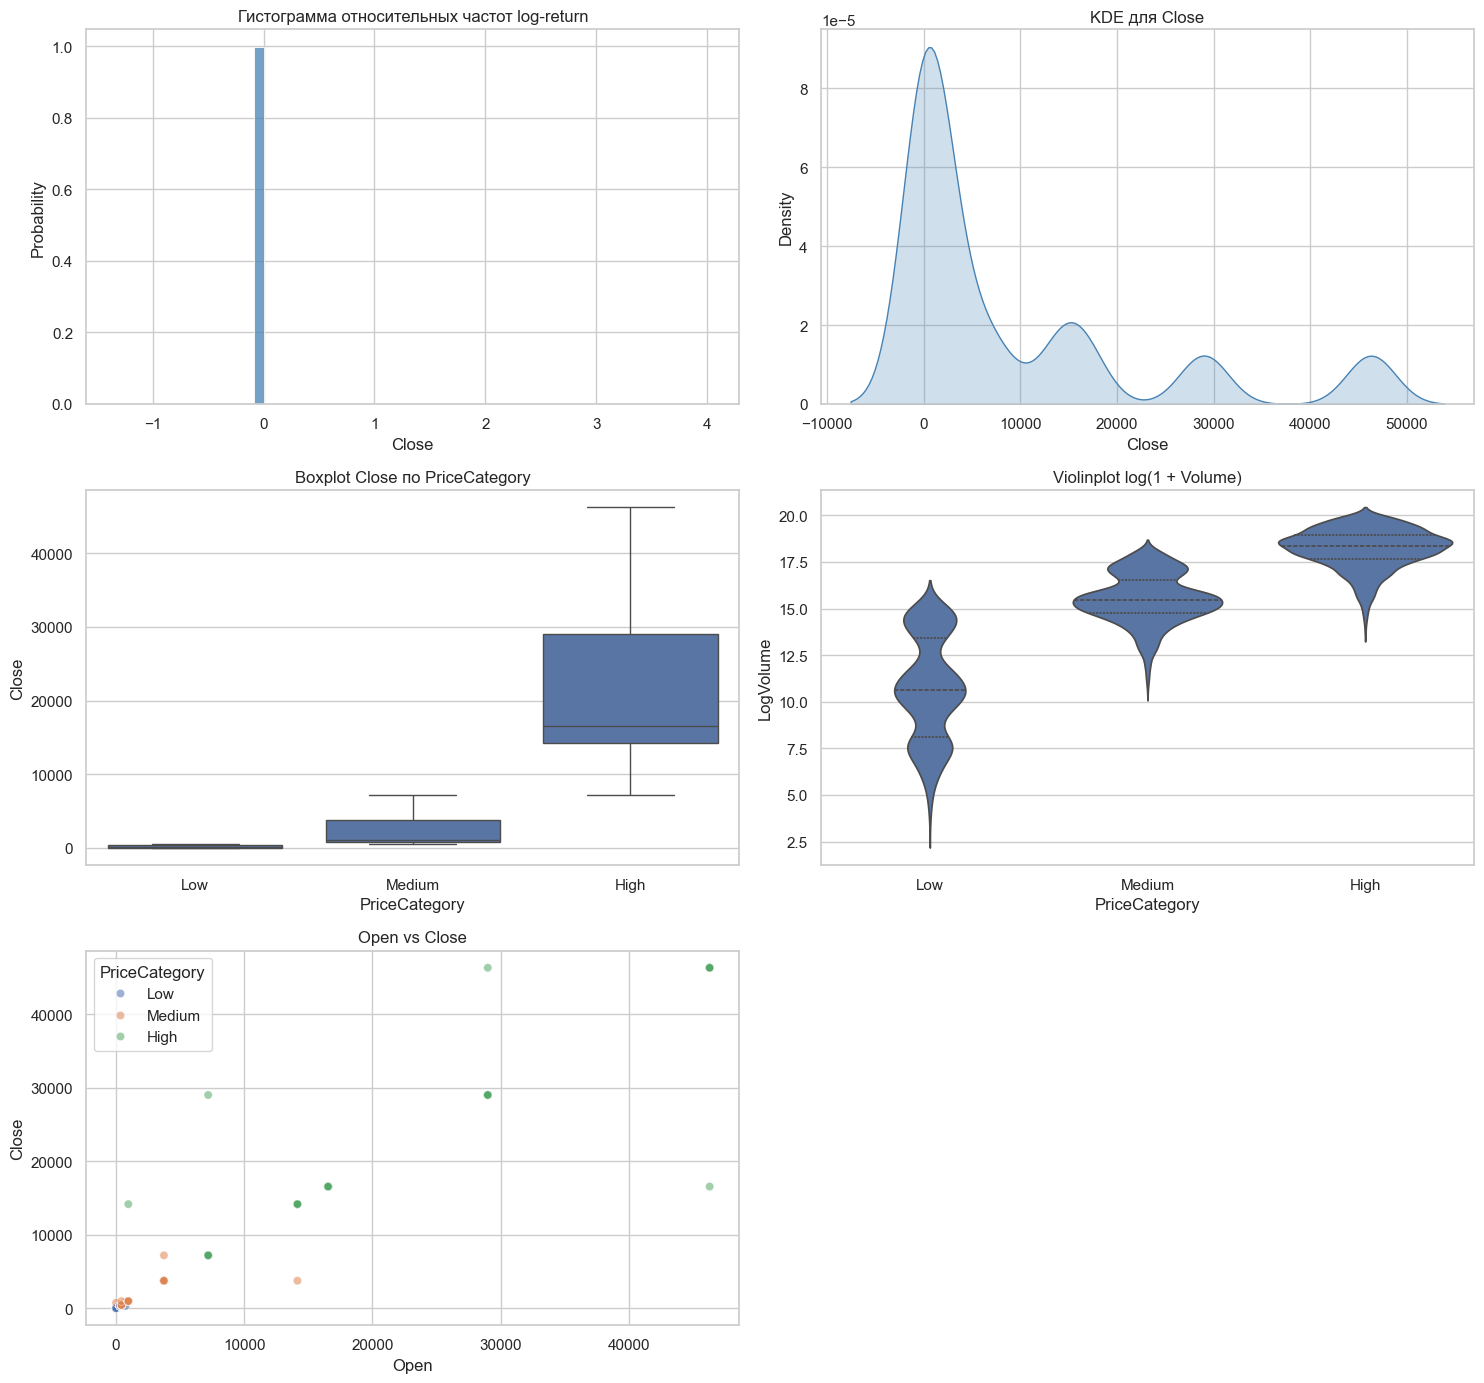

In [10]:
log_returns = np.log(eda_train['Close'] / eda_train['Close'].shift(1)).dropna()
plot_df = eda_train.copy()
plot_df['LogVolume'] = np.log1p(plot_df['Volume'])

fig, axes = plt.subplots(3, 2, figsize=(15, 14))

sns.histplot(log_returns, stat='probability', bins=60, color='steelblue', ax=axes[0, 0])
axes[0, 0].set_title('Гистограмма относительных частот log-return')

sns.kdeplot(data=eda_train, x='Close', fill=True, color='steelblue', ax=axes[0, 1])
axes[0, 1].set_title('KDE для Close')

sns.boxplot(data=eda_train, x='PriceCategory', y='Close', ax=axes[1, 0])
axes[1, 0].set_title('Boxplot Close по PriceCategory')

sns.violinplot(data=plot_df, x='PriceCategory', y='LogVolume', inner='quartile', ax=axes[1, 1])
axes[1, 1].set_title('Violinplot log(1 + Volume)')

sns.scatterplot(data=eda_train, x='Open', y='Close', hue='PriceCategory', alpha=0.55, ax=axes[2, 0])
axes[2, 0].set_title('Open vs Close')

axes[2, 1].axis('off')
plt.tight_layout()
plt.show()

**Вывод:** разные графики отвечают на разные вопросы: histogram показывает относительные частоты, KDE — сглаженную оценку плотности, boxplot — медиану/квартили/потенциальные выбросы, violinplot — форму распределения по группам, scatter — совместное изменение двух числовых признаков. Наличие визуально длинных хвостов само по себе не заменяет статистический тест.

## 7. Проверка нормальности

**Вопрос:** согласуются ли распределения `Close` и логарифмических доходностей с нормальным законом?

Используются тесты D'Agostino–Pearson и Jarque–Bera при уровне значимости \(\alpha=0.05\).

- \(H_0\): распределение совместимо с нормальным;
- если \(p < 0.05\), \(H_0\) отвергается;
- если \(p \ge 0.05\), оснований отвергать \(H_0\) недостаточно.

In [11]:
def normality_tests(series, name, alpha=0.05):
    s = pd.Series(series).replace([np.inf, -np.inf], np.nan).dropna()
    dag_stat, dag_p = stats.normaltest(s)
    jb_stat, jb_p = stats.jarque_bera(s)
    return {
        'Series': name,
        'N': len(s),
        'D_Agostino_stat': dag_stat,
        'D_Agostino_p': dag_p,
        'Jarque_Bera_stat': jb_stat,
        'Jarque_Bera_p': jb_p,
        'Decision_DAgostino': 'reject H0' if dag_p < alpha else 'do not reject H0',
        'Decision_JB': 'reject H0' if jb_p < alpha else 'do not reject H0',
    }

normality = pd.DataFrame([
    normality_tests(eda_train['Close'], 'Close'),
    normality_tests(log_returns, 'Log returns'),
])
display(normality)

for _, r in normality.iterrows():
    print(
        f"{r['Series']}: D'Agostino p={r['D_Agostino_p']:.6g}, "
        f"JB p={r['Jarque_Bera_p']:.6g} -> "
        f"{r['Decision_DAgostino']} / {r['Decision_JB']}"
    )

,Series,N,D_Agostino_stat,D_Agostino_p,Jarque_Bera_stat,Jarque_Bera_p,Decision_DAgostino,Decision_JB
0,Close,4706,"1,284.2471",0.0000,"2,659.6610",0.0000,reject H0,reject H0
1,Log returns,4705,"12,250.7130",0.0000,"271,947,271.5366",0.0000,reject H0,reject H0


Close: D'Agostino p=1.34677e-279, JB p=0 -> reject H0 / reject H0
Log returns: D'Agostino p=0, JB p=0 -> reject H0 / reject H0


**Вывод:** решение о нормальности делается по фактически рассчитанным `p-value` в таблице выше. Формулировка «не отвергаем \(H_0\)» не означает «доказали нормальность». Кроме того, нормальность `Close` или доходностей — не то же самое, что нормальность **ошибок регрессионной модели**.

## 8. One Hot Encoding

**Вопрос:** как перевести искусственный категориальный признак `PriceCategory` в бинарные столбцы и избежать dummy-variable trap?

In [12]:
price_category = pd.Categorical(
    eda_train['PriceCategory'],
    categories=['Low', 'Medium', 'High'],
    ordered=True
)

dummies = pd.get_dummies(price_category, prefix='Cat', drop_first=True, dtype=int)
ohe_demo = pd.concat(
    [eda_train[['Date', 'Close', 'PriceCategory']].reset_index(drop=True), dummies.reset_index(drop=True)],
    axis=1
)
display(ohe_demo.head(12))
print('Dummy columns:', list(dummies.columns))

,Date,Close,PriceCategory,Cat_Medium,Cat_High
0,2010-01-01,0.3000,Low,0,0
1,2010-01-02,0.3000,Low,0,0
2,2010-01-03,0.3000,Low,0,0
3,2010-01-04,0.3000,Low,0,0
4,2010-01-05,0.3000,Low,0,0
5,2010-01-06,0.3000,Low,0,0
6,2010-01-07,0.3000,Low,0,0
7,2010-01-08,0.3000,Low,0,0
8,2010-01-09,0.3000,Low,0,0
9,2010-01-10,0.3000,Low,0,0


Dummy columns: ['Cat_Medium', 'Cat_High']


**Вывод:** при трёх категориях и наличии интерсепта достаточно двух dummy-переменных; одна категория становится базовой. `drop_first=True` устраняет точную линейную зависимость между всеми dummy и константой. Это устраняет именно **dummy-variable trap**, но не гарантирует отсутствие других линейных зависимостей между признаками.

`PriceCategory` здесь создан из `Close` для выполнения пункта OHE. В модели ниже он **не используется**, чтобы не передавать модели искусственно закодированную информацию о цене.

# Задание 2 [4 балла]

1. Выбрать таргет и регрессоры, обосновать их и провести аналитику без утечки из тестовой части.
2. Обучить линейную регрессию без регуляризации и оценить RMSE, MAE, \(R^2\).
3. Обучить регуляризованную линейную модель; выполнить удаление выбросов и нормирование, обосновать методы, использовать `Pipeline`, оценить RMSE, MAE, \(R^2\).

## 2.1. Таргет, признаки и временная постановка

Чтобы задача действительно была прогнозной, используем:

\[
y_t = Close_{t+1}
\]

то есть прогнозируем цену закрытия **следующего дня** по информации, известной после завершения текущего дня \(t\).

Признаки:

- `Open`, `High`, `Low`, `Close` текущего дня;
- `LogVolume = log(1 + Volume)` — логарифм объёма уменьшает влияние масштаба и сильной правой асимметрии;
- `LogReturn_1d` — текущая однодневная лог-доходность;
- `RangePct = (High - Low) / Close` — относительный внутридневной диапазон;
- `SMA_7`, `SMA_30` — скользящие средние, использующие только текущий и прошлые дни.

Все эти величины доступны к концу дня \(t\). Ни один признак не использует данные дня \(t+1\), который является таргетом.

In [13]:
model_df = df.copy()
model_df['LogVolume'] = np.log1p(model_df['Volume'].clip(lower=0))
model_df['LogReturn_1d'] = np.log(model_df['Close'] / model_df['Close'].shift(1))
model_df['RangePct'] = (model_df['High'] - model_df['Low']) / model_df['Close']
model_df['SMA_7'] = model_df['Close'].rolling(7).mean()
model_df['SMA_30'] = model_df['Close'].rolling(30).mean()
model_df['Target_Close_Next_Day'] = model_df['Close'].shift(-1)
model_df['TargetDate'] = model_df['Date'].shift(-1)

features = [
    'Open', 'High', 'Low', 'Close',
    'LogVolume', 'LogReturn_1d', 'RangePct', 'SMA_7', 'SMA_30'
]
target = 'Target_Close_Next_Day'

model_df = model_df.replace([np.inf, -np.inf], np.nan).dropna(
    subset=features + [target, 'TargetDate']
).reset_index(drop=True)

# Разбиваем по дате ТАРГЕТА. Ни один y_train не должен лежать после split_date.
train_model = model_df[model_df['TargetDate'] <= split_date].copy()
test_model = model_df[model_df['TargetDate'] > split_date].copy()

X_train = train_model[features]
y_train = train_model[target]
X_test = test_model[features]
y_test = test_model[target]

print('Train predictors:', train_model['Date'].min().date(), '—', train_model['Date'].max().date())
print('Train targets:   ', train_model['TargetDate'].min().date(), '—', train_model['TargetDate'].max().date())
print('Test predictors: ', test_model['Date'].min().date(), '—', test_model['Date'].max().date())
print('Test targets:    ', test_model['TargetDate'].min().date(), '—', test_model['TargetDate'].max().date())
print('Shapes:', X_train.shape, X_test.shape)

Train predictors: 2010-01-30 — 2022-11-18
Train targets:    2010-01-31 — 2022-11-19
Test predictors:  2022-11-19 — 2026-02-07
Test targets:     2022-11-20 — 2026-02-08
Shapes: (4676, 9) (1177, 9)


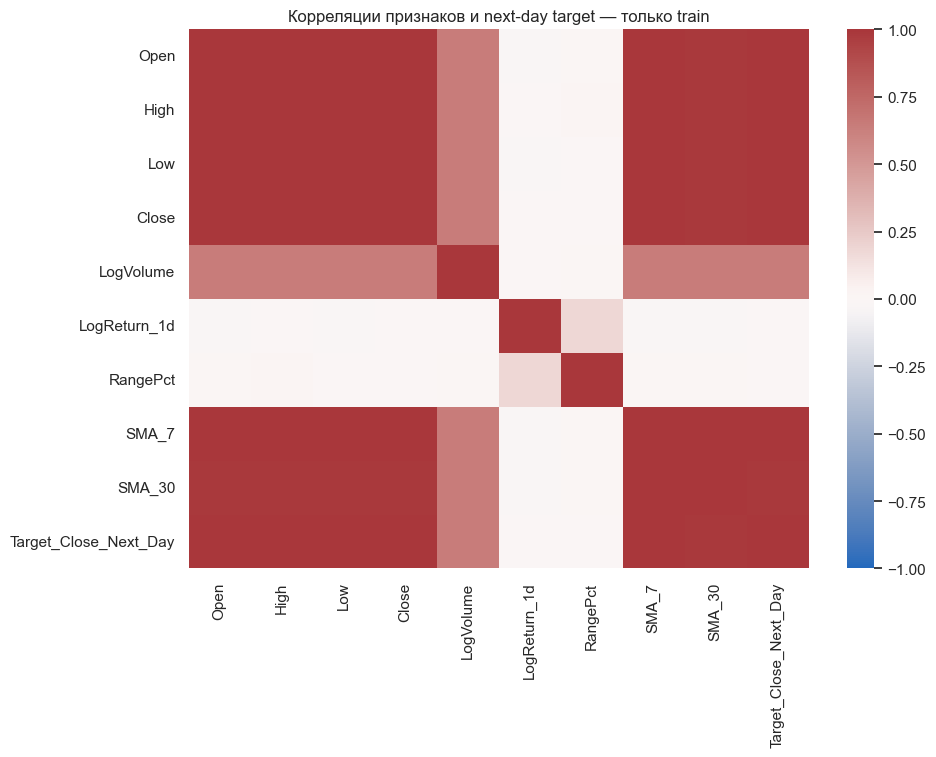

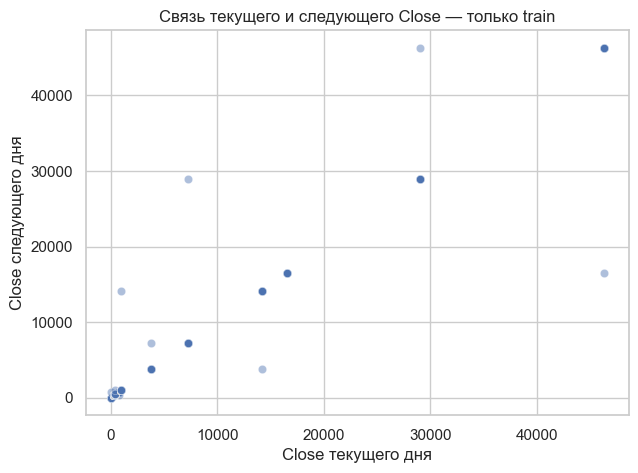

In [14]:
# Аналитика проводится только на train.
train_analysis = X_train.copy()
train_analysis['Target_Close_Next_Day'] = y_train.to_numpy()

plt.figure(figsize=(10, 7))
sns.heatmap(train_analysis.corr(), cmap='vlag', vmin=-1, vmax=1, center=0)
plt.title('Корреляции признаков и next-day target — только train')
plt.show()

plt.figure(figsize=(7, 5))
sns.scatterplot(x=X_train['Close'], y=y_train, alpha=0.45)
plt.xlabel('Close текущего дня')
plt.ylabel('Close следующего дня')
plt.title('Связь текущего и следующего Close — только train')
plt.show()

**Вывод к пункту 1:** временная постановка определяет момент прогноза однозначно: после закрытия дня \(t\) предсказывается `Close` дня \(t+1\). Отложенная часть не использовалась при EDA и выборе признаков. Это снижает риск look-ahead leakage. Высокая корреляция текущих ценовых признаков между собой ожидаема и мотивирует проверку регуляризации, но не означает, что регуляризация обязательно даст лучшую ошибку на тесте.

## 2.2. Линейная регрессия без регуляризации (OLS)

Линейная модель имеет вид

\[
\hat y = b + w_1x_1 + \dots + w_px_p.
\]

OLS выбирает коэффициенты, минимизируя сумму квадратов невязок:

\[
\min_{w,b}\sum_i (y_i-\hat y_i)^2.
\]

Масштабирование не является регуляризацией. Мы используем `StandardScaler` и для OLS, чтобы улучшить численную обусловленность и затем честнее сравнивать OLS и Ridge с одинаковой базовой предобработкой.

In [15]:
def metrics_dict(y_true, y_pred):
    return {
        'RMSE': float(np.sqrt(mean_squared_error(y_true, y_pred))),
        'MAE': float(mean_absolute_error(y_true, y_pred)),
        'R2': float(r2_score(y_true, y_pred)),
    }

ols_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('regressor', LinearRegression())
])
ols_pipe.fit(X_train, y_train)

ols_train_pred = ols_pipe.predict(X_train)
ols_test_pred = ols_pipe.predict(X_test)

ols_metrics = pd.DataFrame([
    {'Model': 'OLS', 'Split': 'Train', **metrics_dict(y_train, ols_train_pred)},
    {'Model': 'OLS', 'Split': 'Test', **metrics_dict(y_test, ols_test_pred)},
])
display(ols_metrics)

# Наивный time-series baseline: завтра ≈ сегодня
naive_test_pred = X_test['Close'].to_numpy()
print('Naive test metrics:', metrics_dict(y_test, naive_test_pred))

,Model,Split,RMSE,MAE,R2
0,OLS,Train,646.4393,35.4570,0.9978
1,OLS,Test,"1,765.7726",168.8844,0.9948


Naive test metrics: {'RMSE': 1762.6308509359517, 'MAE': 86.07553101104503, 'R2': 0.9948353794472584}


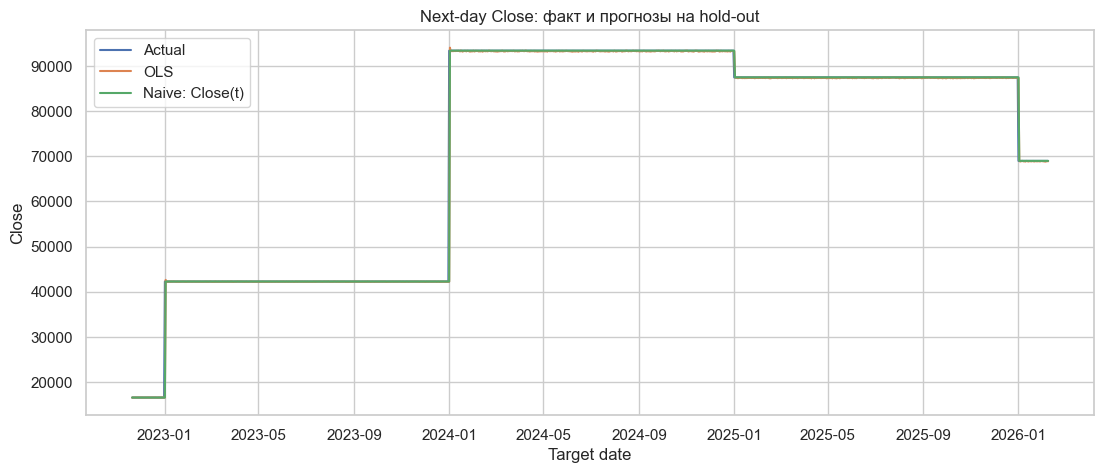

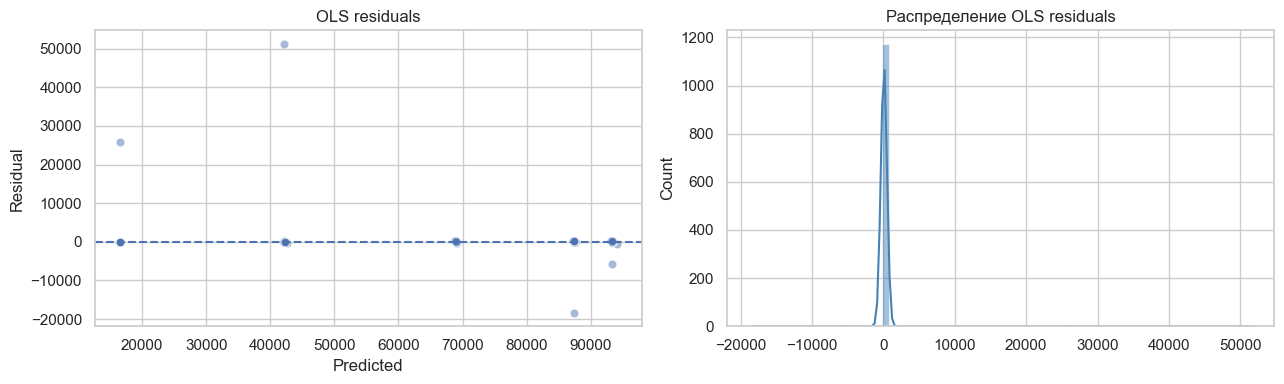

In [16]:
plot_test = test_model[['TargetDate']].copy()
plot_test['Actual'] = y_test.to_numpy()
plot_test['OLS'] = ols_test_pred
plot_test['Naive'] = naive_test_pred

plt.figure(figsize=(13, 5))
plt.plot(plot_test['TargetDate'], plot_test['Actual'], label='Actual')
plt.plot(plot_test['TargetDate'], plot_test['OLS'], label='OLS')
plt.plot(plot_test['TargetDate'], plot_test['Naive'], label='Naive: Close(t)')
plt.title('Next-day Close: факт и прогнозы на hold-out')
plt.xlabel('Target date')
plt.ylabel('Close')
plt.legend()
plt.show()

ols_residuals = y_test.to_numpy() - ols_test_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(x=ols_test_pred, y=ols_residuals, alpha=0.5, ax=axes[0])
axes[0].axhline(0, linestyle='--')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Residual')
axes[0].set_title('OLS residuals')
sns.histplot(ols_residuals, kde=True, color='steelblue', ax=axes[1])
axes[1].set_title('Распределение OLS residuals')
plt.tight_layout()
plt.show()

**Вывод по OLS:** качество необходимо оценивать по напечатанным выше RMSE, MAE и \(R^2\), а также сравнивать с простым baseline `Close(t+1) ≈ Close(t)`. Для временного ряда высокий \(R^2\) сам по себе не доказывает полезность модели: если цены меняются плавно, сильный naive baseline также может давать высокий \(R^2\).

## 2.3. Ridge + удаление выбросов + нормирование + Pipeline

### Удаление выбросов

Удалять выбросы по абсолютному уровню цены некорректно: Bitcoin имеет тренд, поэтому высокая цена позднего периода не является автоматически аномалией. Поэтому IQR применяется к **следующей однодневной лог-доходности** в обучающей части:

\[
r_{t+1}=\ln\frac{Close_{t+1}}{Close_t}.
\]

Используется стандартное правило Tukey:

\[
[Q_1-1.5\,IQR,\; Q_3+1.5\,IQR].
\]

Фильтр вычисляется **только по train**. Тестовые строки никогда не удаляются и не используются для определения границ.

### Нормирование

`StandardScaler` преобразует каждый признак:

\[
z=\frac{x-\mu}{\sigma}.
\]

Это особенно важно для Ridge, потому что штраф \(\alpha\sum_j w_j^2\) зависит от масштаба признаков.

### Ridge

\[
\min_{w,b}\left[\sum_i(y_i-\hat y_i)^2 + \alpha\sum_j w_j^2\right].
\]

`alpha` выбирается только на train через `TimeSeriesSplit`, то есть validation всегда идёт после соответствующей обучающей части.

In [17]:
# Стандартный IQR по next-day log return — только train
train_next_return = np.log(y_train.to_numpy() / X_train['Close'].to_numpy())
train_next_return = pd.Series(train_next_return, index=X_train.index)

q1 = train_next_return.quantile(0.25)
q3 = train_next_return.quantile(0.75)
iqr = q3 - q1
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

keep_mask = train_next_return.between(lower, upper)
X_train_clean = X_train.loc[keep_mask].copy()
y_train_clean = y_train.loc[keep_mask].copy()

print(f'Q1={q1:.6f}, Q3={q3:.6f}, IQR={iqr:.6f}')
print(f'Границы: [{lower:.6f}, {upper:.6f}]')
print(f'Удалено из train: {(~keep_mask).sum():,} из {len(keep_mask):,} '
      f'({(~keep_mask).mean():.2%})')

Q1=0.000000, Q3=0.000000, IQR=0.000000
Границы: [0.000000, 0.000000]
Удалено из train: 12 из 4,676 (0.26%)


In [18]:
ridge_pipe = Pipeline([
    ('scaler', StandardScaler()),
    ('ridge', Ridge())
])

alphas = np.logspace(-4, 4, 41)
tscv = TimeSeriesSplit(n_splits=5)

ridge_search = GridSearchCV(
    estimator=ridge_pipe,
    param_grid={'ridge__alpha': alphas},
    cv=tscv,
    scoring='neg_mean_squared_error',
    n_jobs=-1,
    refit=True,
)
ridge_search.fit(X_train_clean, y_train_clean)

ridge_best = ridge_search.best_estimator_
ridge_train_pred = ridge_best.predict(X_train_clean)
ridge_test_pred = ridge_best.predict(X_test)

print('Best alpha:', ridge_search.best_params_['ridge__alpha'])

ridge_metrics = pd.DataFrame([
    {'Model': 'Ridge', 'Split': 'Train(clean)', **metrics_dict(y_train_clean, ridge_train_pred)},
    {'Model': 'Ridge', 'Split': 'Test', **metrics_dict(y_test, ridge_test_pred)},
])
display(ridge_metrics)

Best alpha: 0.0001


,Model,Split,RMSE,MAE,R2
0,Ridge,Train(clean),0.0335,0.0153,1.0000
1,Ridge,Test,"1,762.6284",86.1944,0.9948


In [19]:
# Контрольное сравнение: OLS и Ridge на ОДИНАКОВОЙ очищенной train-выборке.
# Так мы отделяем эффект регуляризации от эффекта удаления выбросов.
ols_clean = clone(ols_pipe)
ols_clean.fit(X_train_clean, y_train_clean)
ols_clean_test_pred = ols_clean.predict(X_test)

comparison = pd.DataFrame([
    {'Model': 'Naive Close(t)', **metrics_dict(y_test, naive_test_pred)},
    {'Model': 'OLS — all train', **metrics_dict(y_test, ols_test_pred)},
    {'Model': 'OLS — IQR-clean train', **metrics_dict(y_test, ols_clean_test_pred)},
    {'Model': f"Ridge — IQR-clean train (alpha={ridge_search.best_params_['ridge__alpha']:.4g})",
     **metrics_dict(y_test, ridge_test_pred)},
]).sort_values('RMSE')

display(comparison)

,Model,RMSE,MAE,R2
3,Ridge — IQR-clean train (alpha=0.0001),"1,762.6284",86.1944,0.9948
0,Naive Close(t),"1,762.6309",86.0755,0.9948
2,OLS — IQR-clean train,"1,762.6309",86.0755,0.9948
1,OLS — all train,"1,765.7726",168.8844,0.9948


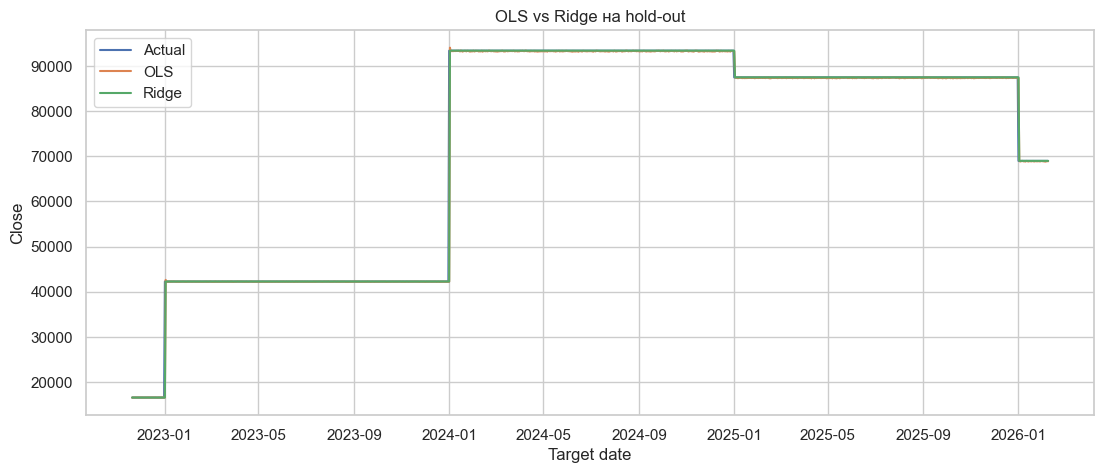

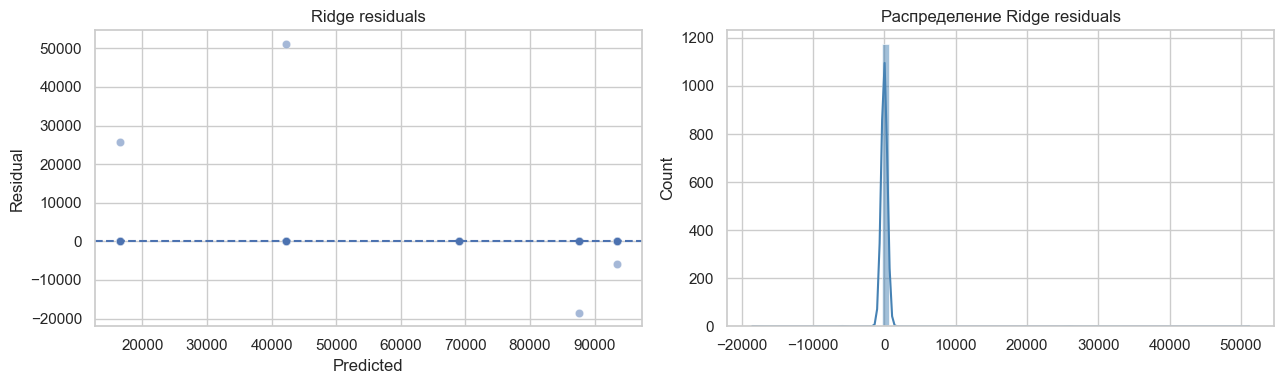

In [20]:
plot_test['Ridge'] = ridge_test_pred

plt.figure(figsize=(13, 5))
plt.plot(plot_test['TargetDate'], plot_test['Actual'], label='Actual')
plt.plot(plot_test['TargetDate'], plot_test['OLS'], label='OLS')
plt.plot(plot_test['TargetDate'], plot_test['Ridge'], label='Ridge')
plt.title('OLS vs Ridge на hold-out')
plt.xlabel('Target date')
plt.ylabel('Close')
plt.legend()
plt.show()

ridge_residuals = y_test.to_numpy() - ridge_test_pred
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.scatterplot(x=ridge_test_pred, y=ridge_residuals, alpha=0.5, ax=axes[0])
axes[0].axhline(0, linestyle='--')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Residual')
axes[0].set_title('Ridge residuals')
sns.histplot(ridge_residuals, kde=True, color='steelblue', ax=axes[1])
axes[1].set_title('Распределение Ridge residuals')
plt.tight_layout()
plt.show()

**Вывод по пункту 3:**

1. Выбросы определяются стандартным IQR-правилом по **доходности**, а не по абсолютной цене, поэтому долгосрочный рост цены сам по себе не считается аномалией.
2. Границы выбросов вычисляются только по train; тест остаётся нетронутым.
3. `StandardScaler` и `Ridge` находятся в одном `Pipeline`, а `alpha` выбирается через `TimeSeriesSplit`, поэтому параметры масштабирования внутри CV обучаются только на соответствующей обучающей части каждого fold.
4. Таблица `comparison` позволяет честно отделить эффект регуляризации от эффекта удаления выбросов: для сравнения OLS и Ridge на одинаковых данных приведён `OLS — IQR-clean train`.
5. Итог о том, какая модель лучше, делается **по фактическим test RMSE/MAE/R²**, а не заранее. Если Ridge не выигрывает у OLS или naive baseline, это также корректный экспериментальный результат.

# Задание 3 [бонус 2 балла]

По итогам лекции №1 ответьте на вопросы о месте искусственного интеллекта среди инноваций в крупной компании (пример «Норильского никеля», видео из группы).

## 1. Какие задачи моделирования и управления решаются?

В видео показаны:

- моделирование буровзрывных работ;
- точная навигация самоходных буровых установок;
- видеоаналитика работы буровых установок;
- определение гранулометрического состава руды;
- управление мельницами самоизмельчения;
- оптимизация процесса флотации;
- ИИ-советчик для печи взвешенной плавки;
- управление процессом продувки расплава в конвертере;
- лазерный контроль строительства и видеоаналитика промышленной безопасности.

Общая цель: по измерениям оценивать состояние технологического процесса и выбирать/рекомендовать такие управляющие воздействия, которые повышают производительность, извлечение полезных компонентов и безопасность.

## 2. Какие разделы/формальные задачи ИИ задействованы?

- **Регрессия** — прогноз непрерывных технологических величин: производительности, извлечения, загрузки и т.п.
- **Классификация** — определение состояния техники: работа, движение, простой, ремонт и др.
- **Компьютерное зрение** — видеоаналитика техники, гранулометрия, контроль строительства и безопасности.
- **Анализ временных рядов** — работа с последовательностями показаний промышленных датчиков.
- **Оптимизация и управление** — подбор режимов мельниц, флотации, печей и конвертеров.
- **Системы поддержки принятия решений** — пример: ИИ-советчик для оператора печи.
- **Генеративный ИИ / NLP** — в видео также показан GPT-помощник.

## 3. Какие физико-химические признаки используются?

Из показанных и естественных для этих процессов признаков можно использовать:

- мощность и загрузку мельницы;
- расходы воды и воздуха;
- размер частиц и гранулометрический состав руды;
- температуру;
- содержание/концентрацию кислорода;
- расход реагентов;
- плотность пульпы и pH;
- химический состав сырья и содержание металлов;
- положение и режим работы оборудования;
- изображения и видео технологического процесса.

Часть признаков прямо видна в видео (например, мощность/загрузка, вода/воздух, гранулометрия, кислород-связанные параметры), а часть допустимо **предположена**, что разрешено формулировкой вопроса.

## 4. Характеристики нескольких признаков

| Признак | Тип | Временная / пространственная дискретность | Сырой или агрегат | Шум / пропуски | Особенности распределения | Потенциал data leakage |
|---|---|---|---|---|---|---|
| Мощность мельницы | Числовой, непрерывный | Частые измерения; конкретная мельница | Обычно сырой сигнал; можно усреднять по минуте | Небольшой измерительный шум; возможны пропуски связи/датчика | Может иметь несколько рабочих режимов, не обязана быть нормальной | Нельзя использовать измерения после момента прогноза |
| Размер частиц / D80 | Числовой | На конкретном участке линии; периодически или непрерывно | Отдельные размеры — сырые; D50/D80 — агрегаты | Камера: пыль, перекрытия, освещение; возможны пропуски | Только положительные значения, часто асимметрия вправо | Нельзя использовать гранулометрию после той стадии, результат которой прогнозируем |
| Состояние буровой установки | Категориальный | По кадрам/коротким временным окнам; конкретная машина | Метка состояния — результат обработки видео; доля времени за смену — агрегат | Ошибки классификации, пропуски видеопотока | Категориальное распределение | Использование будущих кадров для классификации текущего момента даст leakage |
| Содержание кислорода | Числовой, непрерывный | Регулярно; конкретная установка/конвертер | Сырой датчик или rolling-average | Шум, калибровка, возможные пропуски | Физически ограниченный диапазон | Нельзя брать значения, полученные после прогнозируемого состояния |
| Извлечение никеля | Числовой, процент | За технологический интервал/партию | Агрегированный итоговый показатель | Может зависеть от задержанных лабораторных измерений | Ограничено 0–100% и обычно занимает узкий рабочий диапазон | Высокий риск: итоговое извлечение нельзя использовать как признак для предсказания самого этого результата |

**Главный принцип:** при построении модели разрешены только данные, реально доступные в момент выдачи прогноза/управляющего решения.

# Задание 4 [бонус 3 балла]

Показать, что максимизация правдоподобия выборки независимых нормально распределённых невязок приводит к минимизации MSE.

## Доказательство

Пусть

\[
y_i=f(x_i;w)+\varepsilon_i,
\qquad
\varepsilon_i\overset{i.i.d.}{\sim}\mathcal N(0,\sigma^2).
\]

Тогда условная плотность одного наблюдения:

\[
p(y_i\mid x_i,w,\sigma^2)
=
\frac{1}{\sqrt{2\pi\sigma^2}}
\exp\left(
-\frac{(y_i-f(x_i;w))^2}{2\sigma^2}
\right).
\]

Из независимости наблюдений совместное правдоподобие:

\[
L(w,\sigma^2)
=
\prod_{i=1}^{n} p(y_i\mid x_i,w,\sigma^2)
=
(2\pi\sigma^2)^{-n/2}
\exp\left[
-\frac{1}{2\sigma^2}
\sum_{i=1}^{n}(y_i-f(x_i;w))^2
\right].
\]

Логарифм монотонно возрастает, поэтому максимум `L` и максимум `log L` достигаются в одной точке:

\[
\log L(w,\sigma^2)
=
-\frac n2\log(2\pi)
-\frac n2\log(\sigma^2)
-\frac{1}{2\sigma^2}
\sum_{i=1}^{n}(y_i-f(x_i;w))^2.
\]

При фиксированном \(\sigma^2>0\) первые два слагаемых не зависят от \(w\). Следовательно,

\[
\hat w_{MLE}
=
\arg\max_w\log L
=
\arg\min_w
\sum_{i=1}^{n}(y_i-f(x_i;w))^2.
\]

Умножение целевой функции на положительную константу \(1/n\) не меняет точку минимума:

\[
\hat w_{MLE}
=
\arg\min_w
\frac1n\sum_{i=1}^{n}(y_i-f(x_i;w))^2.
\]

Но

\[
MSE(w)=\frac1n\sum_{i=1}^{n}(y_i-f(x_i;w))^2.
\]

Поэтому

\[
\boxed{
\hat w_{MLE}=\arg\min_w MSE(w)
}
\]

при предположении независимых ошибок с нулевым средним и одинаковой нормальной дисперсией.

**Вывод:** метод наименьших квадратов / минимизация MSE является MLE-оцениванием параметров регрессии при i.i.d. Gaussian noise.

# Итог

В работе:

1. данные загружаются напрямую с Kaggle через `kagglehub`;
2. hold-out отделяется до EDA;
3. выполнены все 8 требуемых пунктов EDA;
4. категориальный признак для OHE не используется как скрытая копия таргета в модели;
5. регрессия сформулирована как **next-day forecasting**, поэтому момент доступности признаков определён явно;
6. OLS и Ridge используют одинаковое масштабирование для корректного сравнения;
7. выбросы определяются стандартным IQR по доходности только на train;
8. Ridge настраивается через `TimeSeriesSplit`, а не обычный случайный KFold;
9. итог о качестве моделей делается по реальным test-метрикам и сравнению с naive baseline;
10. заполнены ответы по видео «Норильского никеля» и математическое доказательство MLE → MSE.